In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import re
from textblob import TextBlob
from wordcloud import WordCloud
import cufflinks as cf
import os
from google.colab import files
import plotly.express as px

import warnings
warnings.filterwarnings("ignore")
warnings.warn("This will not show")


In [ ]:
df = pd.read_csv("Reviews.csv", engine='python', on_bad_lines='warn')

In [ ]:
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200834 entries, 0 to 200833
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   Id                      200834 non-null  int64 
 1   ProductId               200834 non-null  object
 2   UserId                  200834 non-null  object
 3   ProfileName             200822 non-null  object
 4   HelpfulnessNumerator    200834 non-null  int64 
 5   HelpfulnessDenominator  200834 non-null  int64 
 6   Score                   200834 non-null  int64 
 7   Time                    200834 non-null  int64 
 8   Summary                 200826 non-null  object
 9   Text                    200834 non-null  object
dtypes: int64(5), object(5)
memory usage: 15.3+ MB


In [ ]:
df.columns

Index(['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator',
       'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text'],
      dtype='object')

In [ ]:
df.isnull().sum()

,0
Id,0
ProductId,0
UserId,0
ProfileName,12
HelpfulnessNumerator,0
HelpfulnessDenominator,0
Score,0
Time,0
Summary,8
Text,0


In [ ]:
df.shape

(200834, 10)

In [ ]:
df1 = df.sort_values('ProductId', axis=0, ascending=True, inplace=False,
                     kind='quicksort', na_position='last')

In [ ]:
# Drop Duplicate
df2=df1.drop_duplicates(subset={"UserId", "ProfileName", "Time", "Text"}, keep='first', inplace=False)

In [ ]:
df3=df2[df2.HelpfulnessNumerator <= df2.HelpfulnessDenominator]


In [ ]:
df3.shape

(163589, 10)

In [ ]:
df3['Score'].value_counts()

,count
Score,
5,103150
4,23787
1,15036
3,12840
2,8776


In [34]:
df3.isnull().sum()

,0
Id,0
ProductId,0
UserId,0
ProfileName,10
HelpfulnessNumerator,0
HelpfulnessDenominator,0
Score,0
Time,0
Summary,1
Text,0


In [ ]:
df4 = df3.dropna(subset=["ProfileName", "Summary"])

In [ ]:
df4.shape

(163578, 10)

In [ ]:
df4["ReviewLength"]=df4["Text"].apply(len)
df4["HelpfulnessRatio"]=((df4["HelpfulnessNumerator"]/df4["HelpfulnessDenominator"]).replace(0,np.nan))

In [ ]:
df4["ReviewDate"] = pd.to_datetime(df4["Time"], unit="s")
df4["Year"] = df4["ReviewDate"].dt.year
df4["Month"] = df4["ReviewDate"].dt.month
df4["YearMonth"] = df4["ReviewDate"].dt.to_period("M").astype(str)

In [ ]:
df4.drop(columns=["Time"], inplace=True)
df4.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Summary,Text,ReviewLength,HelpfulnessRatio,ReviewDate,Year,Month,YearMonth
24749,24750,2734888454,A13ISQV0U9GZIC,Sandikaye,1,1,2,made in china,My dogs loves this chicken but its a product f...,320,1.000000,2007-10-11,2007,10,2007-10
24750,24751,2734888454,A1C298ITT645B6,Hugh G. Pritchard,0,0,5,Dog Lover Delites,Our dogs just love them. I saw them in a pet ...,150,NaN,2007-11-25,2007,11,2007-11
150525,150526,6641040,A3E9QZFE9KXH8J,R. Mitchell,11,18,1,awesome book poor size,This is one of the best children's books ever ...,231,0.611111,2005-10-17,2005,10,2005-10
150511,150512,6641040,A1DJXZA5V5FFVA,A. Conway,0,0,5,Must have.,I set aside at least an hour each day to read ...,567,NaN,2012-05-29,2012,5,2012-05
150512,150513,6641040,ASH0DZQQF6AIZ,tessarat,0,0,5,A classic,I remembered this book from my childhood and g...,203,NaN,2012-01-05,2012,1,2012-01


In [ ]:
reviews = df4.copy()

In [ ]:
reviews.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Summary,Text,ReviewLength,HelpfulnessRatio,ReviewDate,Year,Month,YearMonth
24749,24750,2734888454,A13ISQV0U9GZIC,Sandikaye,1,1,2,made in china,My dogs loves this chicken but its a product f...,320,1.000000,2007-10-11,2007,10,2007-10
24750,24751,2734888454,A1C298ITT645B6,Hugh G. Pritchard,0,0,5,Dog Lover Delites,Our dogs just love them. I saw them in a pet ...,150,NaN,2007-11-25,2007,11,2007-11
150525,150526,6641040,A3E9QZFE9KXH8J,R. Mitchell,11,18,1,awesome book poor size,This is one of the best children's books ever ...,231,0.611111,2005-10-17,2005,10,2005-10
150511,150512,6641040,A1DJXZA5V5FFVA,A. Conway,0,0,5,Must have.,I set aside at least an hour each day to read ...,567,NaN,2012-05-29,2012,5,2012-05
150512,150513,6641040,ASH0DZQQF6AIZ,tessarat,0,0,5,A classic,I remembered this book from my childhood and g...,203,NaN,2012-01-05,2012,1,2012-01


#Text Preprocessing


In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 30.9 MB/s  0:00:00


In [ ]:
from tqdm import tqdm
from bs4 import BeautifulSoup
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from gensim.models import Word2Vec
nltk.download('punkt_tab')
nltk.download('stopwords')
from nltk.corpus import stopwords
STOPWORDS = set(stopwords.words('english'))

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
def decontracted(phrase):
    # specific
    phrase = re.sub(r"won't", "will not", phrase)
    phrase = re.sub(r"can\'t", "can not", phrase)

    # general
    phrase = re.sub(r"n\'t", " not", phrase)
    phrase = re.sub(r"\'re", " are", phrase)
    phrase = re.sub(r"\'s", " is", phrase)
    phrase = re.sub(r"\'d", " would", phrase)
    phrase = re.sub(r"\'ll", " will", phrase)
    phrase = re.sub(r"\'t", " not", phrase)
    phrase = re.sub(r"\'ve", " have", phrase)
    phrase = re.sub(r"\'m", " am", phrase)
    return phrase

In [ ]:
txt_preprocessed = []
for i in tqdm(reviews['Text'].values):
    i = re.sub(r"http\S+", "", i)
    i = BeautifulSoup(i, 'lxml').get_text()
    i = decontracted(i)
    i = re.sub("\S*\d\S*", "", i).strip()
    i = re.sub('[^A-Za-z]+', ' ', i)
    txt_preprocessed.append(i.lower().strip())

100%|██████████| 163578/163578 [01:14<00:00, 2187.45it/s]


In [ ]:
txt_preprocessed[1500]

'i was introduced to cavender is greek seasoning several years ago at a greek festival it is so versatile i use it to blacken steaks grill pork chops season gravy is season hamburgers on potatoes i give as gifts to friends i love it so much'

In [ ]:
#TF-IDF

tf_idf_vect = TfidfVectorizer(ngram_range=(1,2), min_df=10)
tf_idf_vect.fit(txt_preprocessed)
final_tf_idf = tf_idf_vect.transform(txt_preprocessed)
print("The type of count vectorizer",type(final_tf_idf))
print("The shape of out text TFIDF vectorizer",final_tf_idf.get_shape())
print("The number of unique words including both unigrams and bigrams", final_tf_idf.get_shape()[1])
print(tf_idf_vect.idf_)

The type of count vectorizer <class 'scipy.sparse._csr.csr_matrix'>
The shape of out text TFIDF vectorizer (163578, 135109)
The number of unique words including both unigrams and bigrams 135109
[ 9.53931543  9.91400888  9.57106413 ...  7.9877715   8.72838521
 10.60715606]


In [35]:
#Word2Vec

i=0
list_of_sent=[]
for sentence in txt_preprocessed:
    list_of_sent.append(sentence.split())

In [ ]:
w2v_model = Word2Vec(
    list_of_sent,
    min_count=5,
    vector_size=50,
    workers=4
)
print(w2v_model.wv.most_similar('great'))
print(w2v_model.wv.most_similar('worst'))

[('fantastic', 0.9187498688697815), ('terrific', 0.9159038662910461), ('wonderful', 0.8638004660606384), ('fabulous', 0.8415613174438477), ('good', 0.8272233605384827), ('awesome', 0.8082536458969116), ('perfect', 0.8049020171165466), ('decent', 0.7518270015716553), ('excellent', 0.7459144592285156), ('nice', 0.7393020391464233)]
[('greatest', 0.8093427419662476), ('nastiest', 0.7940173745155334), ('best', 0.793975830078125), ('tastiest', 0.7082810401916504), ('strongest', 0.6902723908424377), ('smoothest', 0.6701875925064087), ('sweetest', 0.6432446837425232), ('terrible', 0.633160412311554), ('horrible', 0.6321743726730347), ('hottest', 0.6311309933662415)]


In [ ]:
w2v_words = list(w2v_model.wv.key_to_index.keys())
print("number of words that occured minimum 5 times ",len(w2v_words))
print("sample words ", w2v_words[0:50])

number of words that occured minimum 5 times  23556
sample words  ['the', 'i', 'and', 'a', 'it', 'is', 'to', 'of', 'this', 'not', 'in', 'for', 'my', 'that', 'have', 'but', 'you', 'are', 'with', 'was', 'they', 'as', 'on', 'like', 'so', 'these', 'them', 'good', 'be', 'or', 'at', 'will', 'taste', 'can', 'one', 'just', 'if', 'very', 'do', 'great', 'would', 'coffee', 'all', 'product', 'am', 'from', 'flavor', 'we', 'when', 'more']


In [ ]:
#Avg W2v

sent_vectors = []; # the avg-w2v for each sentence/review is stored in this list
for sent in tqdm(list_of_sent): # for each review/sentence
    sent_vec = np.zeros(50) # as word vectors are of zero length
    cnt_words =0; # num of words
    for word in sent: # for each word in a review/sentence
        if word in w2v_words:
            vec = w2v_model.wv[word]
            sent_vec += vec
            cnt_words += 1
    if cnt_words != 0:
            sent_vec /= cnt_words
    sent_vectors.append(sent_vec)
print(len(sent_vectors))
print(len(sent_vectors[0]))

100%|██████████| 163578/163578 [08:15<00:00, 330.32it/s]

163578
50


In [36]:
#TF-IDF weighted W2v

model = TfidfVectorizer()
model.fit(txt_preprocessed)
# we are converting a dictionary with word as a key, and the idf as a value
dictionary = dict(zip(model.get_feature_names_out(), list(model.idf_)))

ifidf_feat = model.get_feature_names_out()
tfidf_sent_vectors = []; # the tfidf-w2v for each sentence/review is stored in this list
row=0;
for sent in tqdm(list_of_sent): # for each review/sentence
    sent_vec = np.zeros(50) # as word vectors are of zero length
    weight_sum =0; # num of words
    for word in sent: # for each word in a review/sentence
        if word in w2v_words and word in ifidf_feat:
            vec = w2v_model.wv[word]
            tf_idf = dictionary[word]*(sent.count(word)/len(sent))
            sent_vec += (vec * tf_idf)
            weight_sum += tf_idf
    if weight_sum != 0:
            sent_vec /= weight_sum
    tfidf_sent_vectors.append(sent_vec)
    row += 1

  1%|          | 1406/163578 [09:26<18:08:49,  2.48it/s]


KeyboardInterrupt: 

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

In [ ]:
stop = set(stopwords.words('english'))
def tokenizeandstopwords(Text):
    tokens = nltk.word_tokenize(Text)
    # taken only words (not punctuation)
    token_words = [w for w in tokens if w.isalpha()]
    meaningful_words = [w for w in token_words if not w in stop]
    joined_words = ( " ".join(meaningful_words))
    return joined_words
reviews['Text'] = reviews['Text'].apply(tokenizeandstopwords)

In [37]:
def generate_ngrams(text, n_gram=1):
    token = [token for token in text.lower().split(' ') if token != '' if token not in STOPWORDS]
    ngrams = zip(*[token[i:] for i in range(n_gram)])
    return [' '.join(ngram) for ngram in ngrams]
N=10
reviews['Text'] = [' '.join(df['Text'][i].split()) for i in range(len(reviews))]
reviews['Text']=reviews['Text'].str.replace("br","")

In [38]:
from collections import defaultdict
less_toxic_unigrams = defaultdict(int)
for tweet in reviews['Text']:
    for word in generate_ngrams(tweet, 1):
        less_toxic_unigrams[word] += 1

df_less_toxic_unigrams = pd.DataFrame(sorted(less_toxic_unigrams.items(), key=lambda x: x[1])[::-1])

unigrams_less_11 = df_less_toxic_unigrams[:N]

fig = px.bar(x=unigrams_less_11[1], y=unigrams_less_11[0], orientation='h',color =unigrams_less_11[0],color_discrete_sequence = ["#004529","#f6fcb8"])
fig.update_layout(title = "<b> Top 10 Most Common Uni-grams In Text </b>",xaxis_title="",yaxis_title="<b> Frequency </b>",font_size=18, plot_bgcolor="#fff",showlegend=False)

#Sentiment

In [39]:
def sentiment(score):
    if score <= 2:
        return 'Negative'
    elif score == 3:
        return 'Neutral'
    else:
        return 'Positive'

reviews['Sentiment'] = reviews['Score'].apply(sentiment)
print(reviews['Sentiment'].value_counts())

Sentiment
Positive    126929
Negative     23809
Neutral      12840
Name: count, dtype: int64


In [40]:
sentiment_percentage = reviews['Sentiment'].value_counts(normalize=True) * 100
print(sentiment_percentage)

Sentiment
Positive    77.595398
Negative    14.555136
Neutral      7.849466
Name: proportion, dtype: float64


In [41]:
pd.crosstab(reviews['Score'], reviews['Sentiment'])

Sentiment,Negative,Neutral,Positive
Score,,,
1,15035,0,0
2,8774,0,0
3,0,12840,0
4,0,0,23787
5,0,0,103142


In [42]:
from collections import defaultdict

positive_unigrams = defaultdict(int)

positive_reviews = reviews[reviews['Score'].isin([4, 5])]
for review in positive_reviews['Text']:
    for word in generate_ngrams(review, 1):
        positive_unigrams[word] += 1


positive_words = pd.DataFrame(
    sorted(
        positive_unigrams.items(),
        key=lambda x: x[1],
        reverse=True
    ),
    columns=['Word', 'Frequency']
)

print(positive_words.head(10))

     Word  Frequency
0     /><      59647
1    like      55408
2     one      34306
3    good      33437
4   great      29388
5   taste      28593
6   would      28012
7  coffee      27838
8    love      27129
9     get      23778


In [43]:
negative_unigrams = defaultdict(int)
negative_reviews = reviews[reviews['Score'].isin([1, 2])]

for review in negative_reviews['Text']:
    for word in generate_ngrams(review, 1):
        negative_unigrams[word] += 1



negative_words = pd.DataFrame(
    sorted(
        negative_unigrams.items(),
        key=lambda x: x[1],
        reverse=True
    ),
    columns=['Word', 'Frequency']
)

print(negative_words.head(10))

     Word  Frequency
0     /><      11200
1    like      10502
2    good       6267
3     one       6245
4   great       5508
5   taste       5501
6   would       5215
7  coffee       5132
8    love       5086
9     get       4377


#Positive and negative bigram

In [44]:
positive_bigrams = defaultdict(int)

for review in positive_reviews['Text']:
    for bigram in generate_ngrams(review, 2):
        positive_bigrams[bigram] += 1

positive_bigrams_df = pd.DataFrame(
    sorted(
        positive_bigrams.items(),
        key=lambda x: x[1],
        reverse=True
    ),
    columns=['Bigram', 'Frequency']
)

print(positive_bigrams_df.head(10))

             Bigram  Frequency
0           />< />i       9335
1         />< />the       5162
2        taste like       2747
3  highly recommend       2640
4       tastes like       2333
5     peanut butter       2295
6        />< />this       2146
7         green tea       2095
8       much better       1991
9       really like       1969


In [45]:
negative_bigrams = defaultdict(int)

for review in negative_reviews['Text']:
    for bigram in generate_ngrams(review, 2):
        negative_bigrams[bigram] += 1

negative_bigrams_df = pd.DataFrame(
    sorted(
        negative_bigrams.items(),
        key=lambda x: x[1],
        reverse=True
    ),
    columns=['Bigram', 'Frequency']
)

print(negative_bigrams_df.head(10))

             Bigram  Frequency
0           />< />i       1745
1         />< />the        956
2        taste like        561
3       tastes like        486
4  highly recommend        484
5         green tea        419
6          dog food        391
7       much better        388
8     peanut butter        386
9       really like        384


## **Univariate Analysis**

In [46]:
reviews.describe()

,Id,HelpfulnessNumerator,HelpfulnessDenominator,Score,ReviewLength,HelpfulnessRatio,ReviewDate,Year,Month
count,163578.000000,163578.000000,163578.000000,163578.000000,163578.000000,76370.000000,163578,163578.000000,163578.000000
mean,99495.595422,1.700137,2.171979,4.169026,439.387295,0.876931,2011-02-01 00:57:32.239298816,2010.592439,6.444314
min,1.000000,0.000000,0.000000,1.000000,18.000000,0.022222,1999-10-08 00:00:00,1999.000000,1.000000
25%,49913.250000,0.000000,0.000000,4.000000,183.000000,0.800000,2010-04-18 00:00:00,2010.000000,3.000000
50%,98209.500000,0.000000,1.000000,5.000000,307.000000,1.000000,2011-07-22 00:00:00,2011.000000,7.000000
75%,148985.750000,2.000000,2.000000,5.000000,535.000000,1.000000,2012-03-26 00:00:00,2012.000000,9.000000
max,200834.000000,866.000000,878.000000,5.000000,16952.000000,1.000000,2012-10-26 00:00:00,2012.000000,12.000000
std,57635.372658,6.774539,7.389302,1.312343,435.897260,0.219088,NaN,1.519703,3.385073


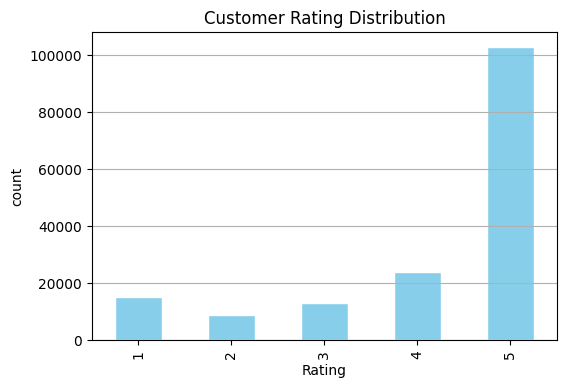

In [47]:
reviews["Score"].value_counts().sort_index().plot(
    kind="bar",
    color="skyblue",
    edgecolor="white",
    figsize=(6,4)
)
plt.xlabel('Rating')
plt.ylabel('count')
plt.title('Customer Rating Distribution')
plt.grid(axis="y")
plt.show()

**Most of the customer gave 5 rating**

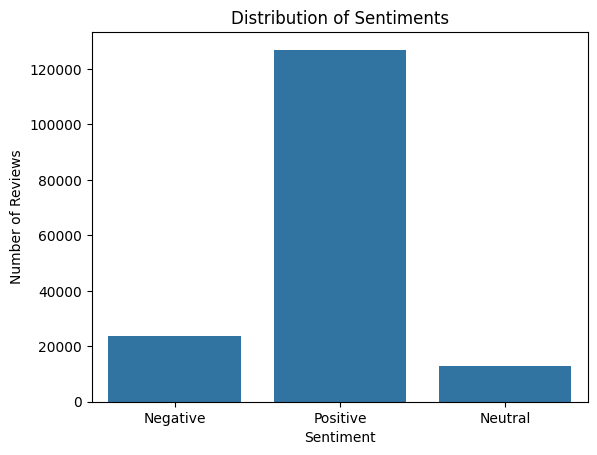

In [48]:
sns.countplot(x='Sentiment', data=reviews)

plt.title('Distribution of Sentiments')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

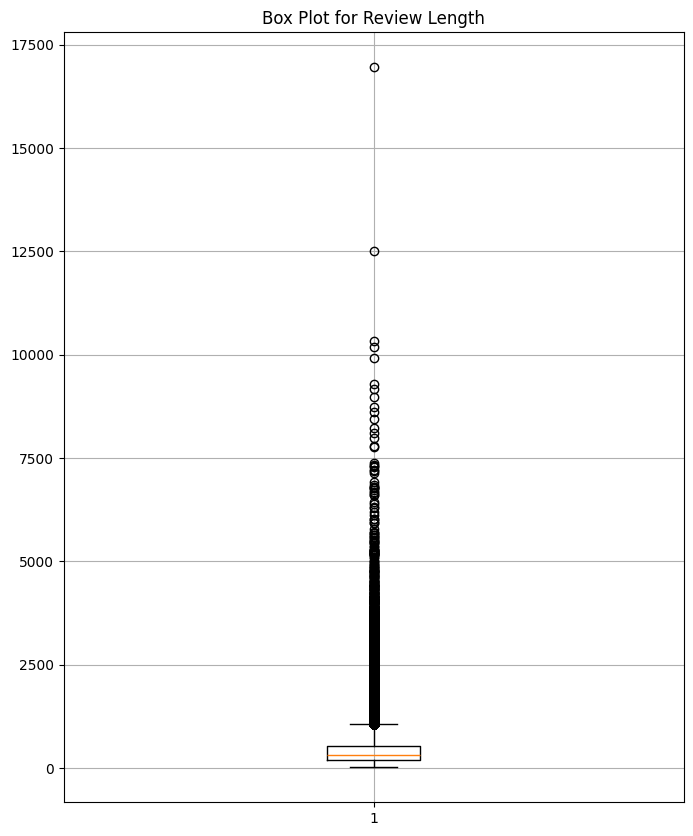

In [49]:
plt.figure(figsize=(8, 10))
plt.boxplot(reviews['ReviewLength'])
plt.title("Box Plot for Review Length")
plt.grid()
plt.show()

This boxplot shows most customer reviews are short.The review length distribution is highly positively skewed.There are many genuine long-review outliers.

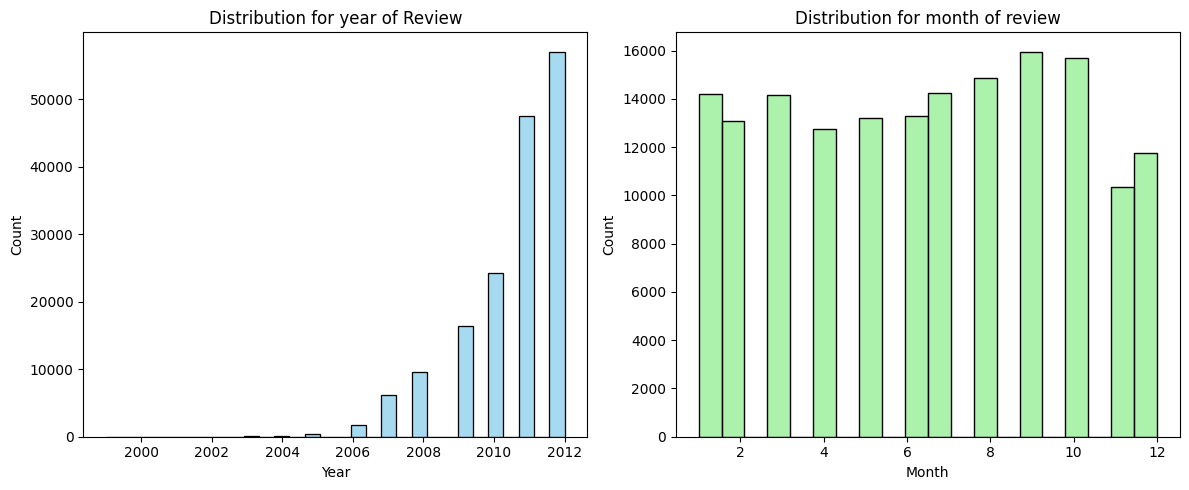

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(reviews["Year"], bins=30, color="skyblue", ax=axes[0])
axes[0].set_title("Distribution for year of Review")

sns.histplot(reviews["Month"].dropna(), bins=20, color="lightgreen", ax=axes[1])
axes[1].set_title("Distribution for month of review")

plt.tight_layout()
plt.show()

Most of the customer parchase the fine food product in 2012 and there is not much difference in monthly parchase, however september has little bit higher parchase.


In [51]:
reviews["ProductId"].value_counts()

,count
ProductId,
B0026RQTGE,630
B001EO5Q64,566
B0013NUGDE,562
B000KV61FC,556
B005K4Q37A,541
...,...
B009LSMTWE,1
B009KUFALA,1
B009KOHGEK,1


Hence **B007JFMH8M**	is the maximum parchased product.

In [52]:
reviews["UserId"].value_counts()

,count
UserId,
A3OXHLG6DIBRW8,124
AY12DBB0U420B,121
A1YUL9PCJR3JTY,92
A1Z54EM24Y40LL,91
A281NPSIMI1C2R,90
...,...
A2W20ABT8G75VH,1
A1HJFS9XQC5DOD,1
A2ZRHLXWJ5J8GX,1


**AY12DBB0U420B** is an active customer for purchasing fine food product.

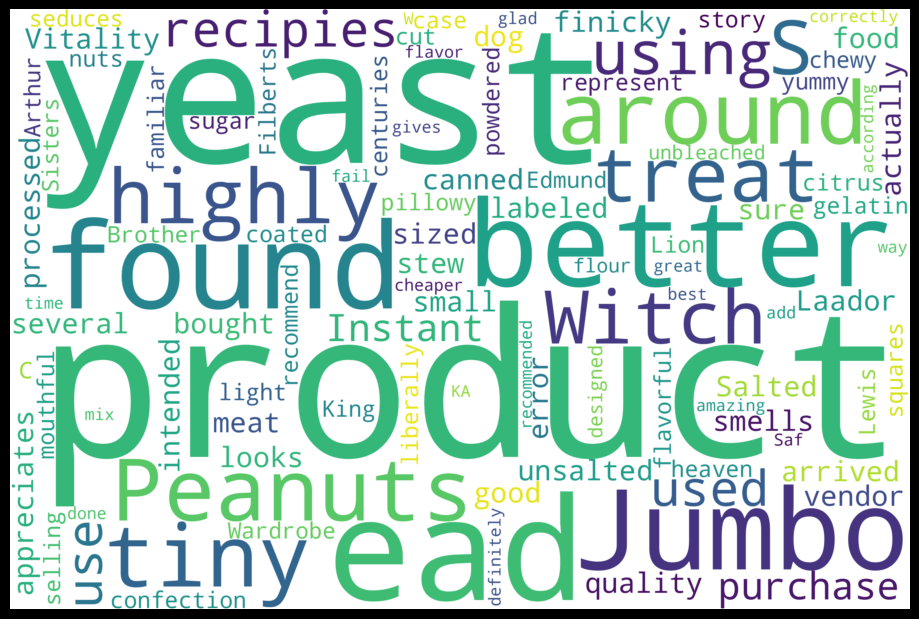

In [53]:
def generate_word_cloud(Text):
    wordcloud = WordCloud(
        background_color='white',
        width = 3000,
        height = 2000).generate(str(Text))
    fig = plt.figure(
        figsize = (14, 6),
        facecolor = 'k',
        edgecolor = 'k')
    plt.imshow(wordcloud, interpolation = 'bilinear')
    plt.axis('off')
    plt.tight_layout(pad=0)
    plt.show()

df_text = reviews.Text.values
generate_word_cloud(df_text)

## **Bivariate Analysis**

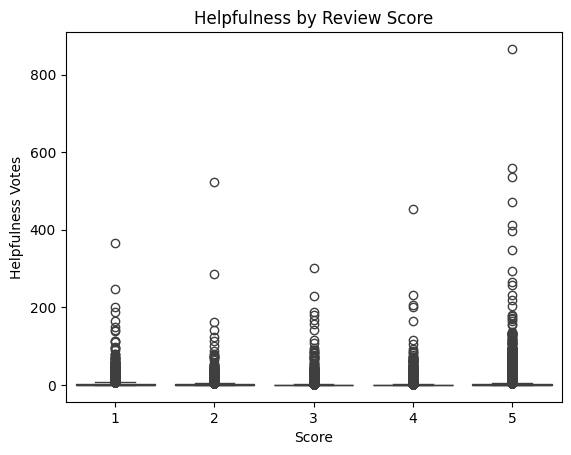

In [54]:
#score vs helpfulness
sns.boxplot(x='Score', y='HelpfulnessNumerator', data=reviews)
plt.xlabel('Score')
plt.ylabel('Helpfulness Votes')
plt.title('Helpfulness by Review Score')
plt.show()

In [55]:
reviews.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Summary,Text,ReviewLength,HelpfulnessRatio,ReviewDate,Year,Month,YearMonth,Sentiment
24749,24750,2734888454,A13ISQV0U9GZIC,Sandikaye,1,1,2,made in china,I have bought several of the Vitality canned d...,320,1.000000,2007-10-11,2007,10,2007-10,Negative
24750,24751,2734888454,A1C298ITT645B6,Hugh G. Pritchard,0,0,5,Dog Lover Delites,Product arrived labeled as Jumbo Salted Peanut...,150,NaN,2007-11-25,2007,11,2007-11,Positive
150525,150526,6641040,A3E9QZFE9KXH8J,R. Mitchell,11,18,1,awesome book poor size,This is a confection that has been around a fe...,231,0.611111,2005-10-17,2005,10,2005-10,Negative
150511,150512,6641040,A1DJXZA5V5FFVA,A. Conway,0,0,5,Must have.,If you are looking for the secret ingredient i...,567,NaN,2012-05-29,2012,5,2012-05,Positive
150512,150513,6641040,ASH0DZQQF6AIZ,tessarat,0,0,5,A classic,Great taffy at a great price. There was a wide...,203,NaN,2012-01-05,2012,1,2012-01,Positive


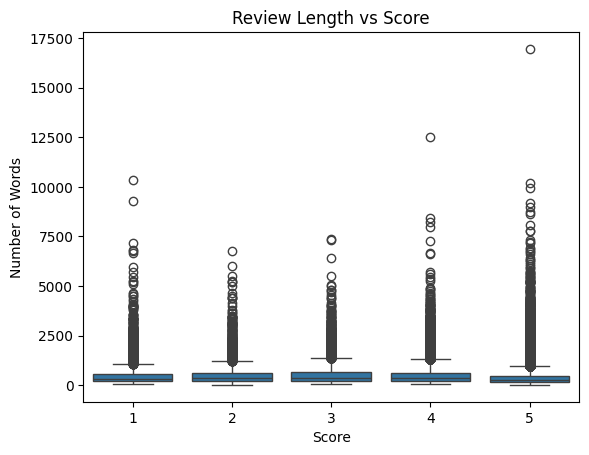

In [56]:
sns.boxplot(x='Score', y='ReviewLength', data=reviews)

plt.xlabel('Score')
plt.ylabel('Number of Words')
plt.title('Review Length vs Score')
plt.show()

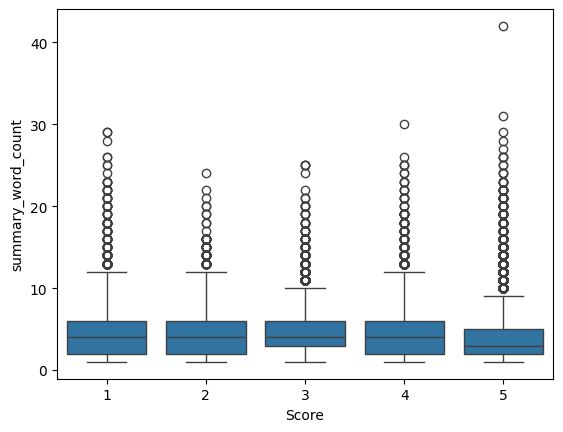

In [57]:
reviews['summary_word_count'] = reviews['Summary'].fillna('').str.split().str.len()
sns.boxplot(x='Score', y='summary_word_count', data=reviews)
plt.show()

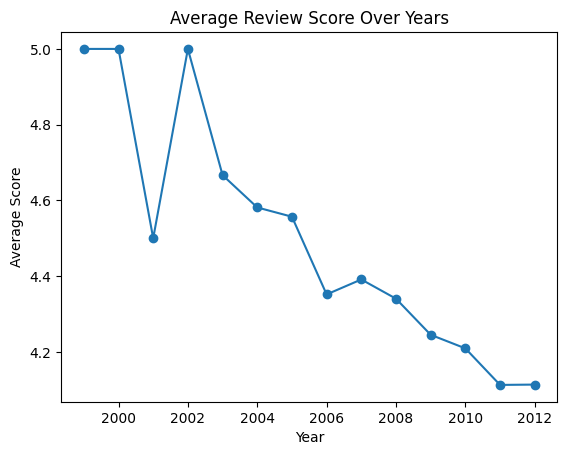

In [58]:
year_score = reviews.groupby('Year')['Score'].mean()

year_score.plot(kind='line', marker='o')
plt.xlabel('Year')
plt.ylabel('Average Score')
plt.title('Average Review Score Over Years')
plt.show()

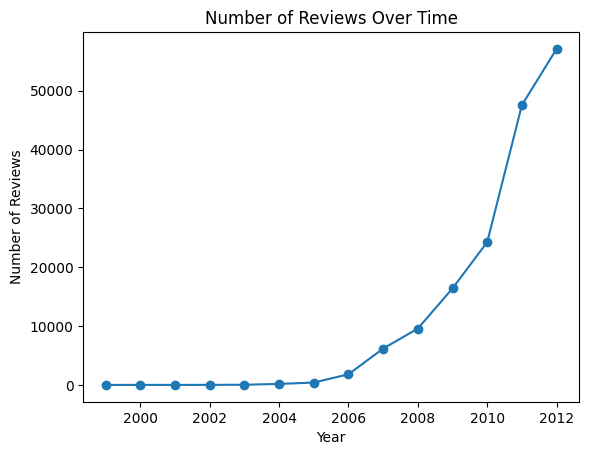

In [59]:
year_count = reviews.groupby('Year').size()

year_count.plot(kind='line', marker='o')
plt.xlabel('Year')
plt.ylabel('Number of Reviews')
plt.title('Number of Reviews Over Time')
plt.show()

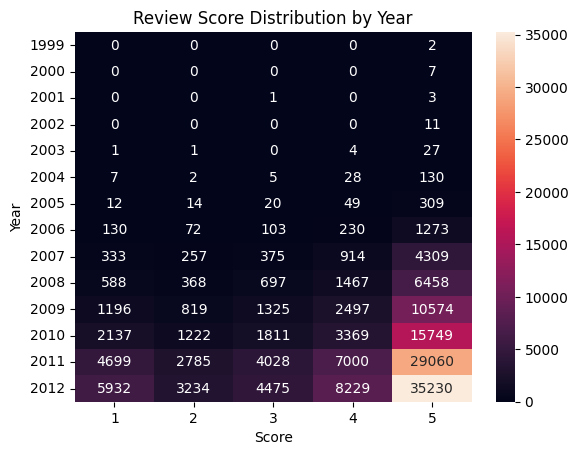

In [60]:
score_year = pd.crosstab(reviews['Year'], reviews['Score'])

sns.heatmap(score_year, annot=True, fmt='d')
plt.xlabel('Score')
plt.ylabel('Year')
plt.title('Review Score Distribution by Year')
plt.show()

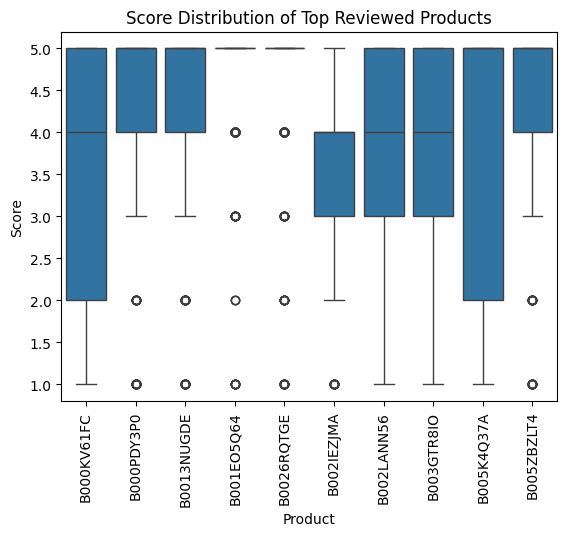

In [61]:
top_products = reviews['ProductId'].value_counts().head(10).index

product_score = reviews[reviews['ProductId'].isin(top_products)]

sns.boxplot(
    x='ProductId',
    y='Score',
    data=product_score
)

plt.xticks(rotation=90)
plt.xlabel('Product')
plt.ylabel('Score')
plt.title('Score Distribution of Top Reviewed Products')
plt.show()

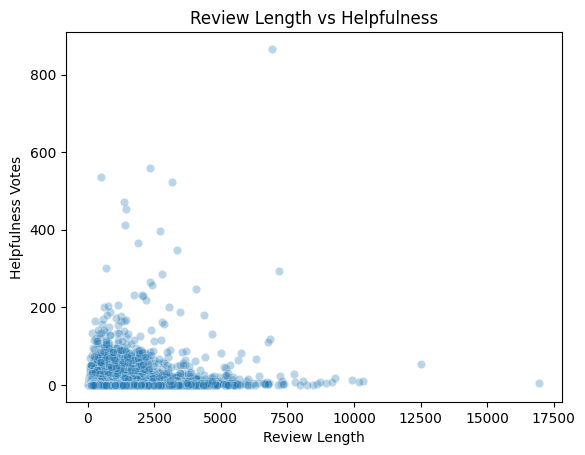

In [62]:
sns.scatterplot(
    x='ReviewLength',
    y='HelpfulnessNumerator',
    data=reviews,
    alpha=0.3
)

plt.xlabel('Review Length')
plt.ylabel('Helpfulness Votes')
plt.title('Review Length vs Helpfulness')
plt.show()

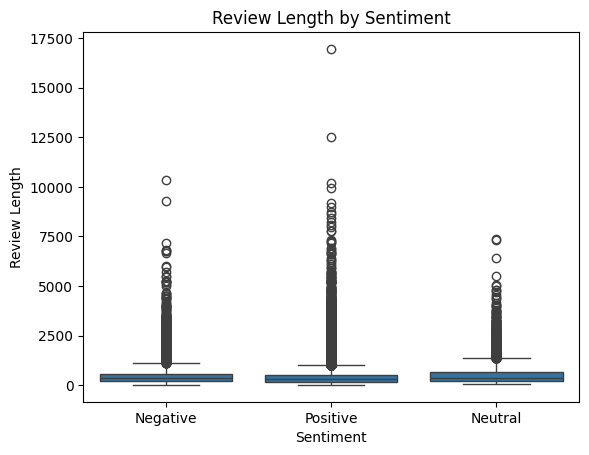

In [63]:
sns.boxplot(
    x='Sentiment',
    y='ReviewLength',
    data=reviews
)

plt.xlabel('Sentiment')
plt.ylabel('Review Length')
plt.title('Review Length by Sentiment')
plt.show()

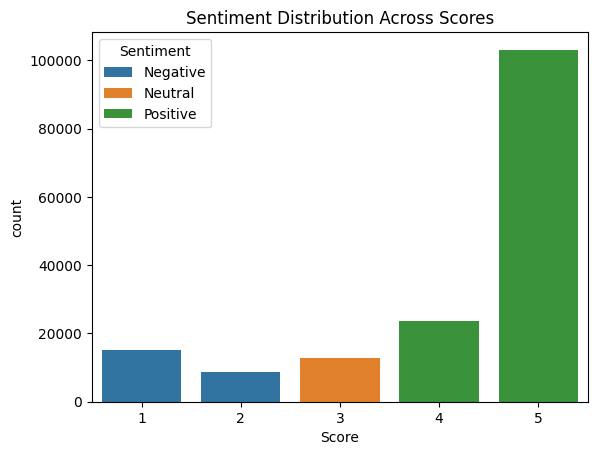

In [64]:
pd.crosstab(reviews['Score'], reviews['Sentiment'])
sns.countplot(
    x='Score',
    hue='Sentiment',
    data=reviews
)

plt.title('Sentiment Distribution Across Scores')
plt.show()

## **Multivariate Analysis**

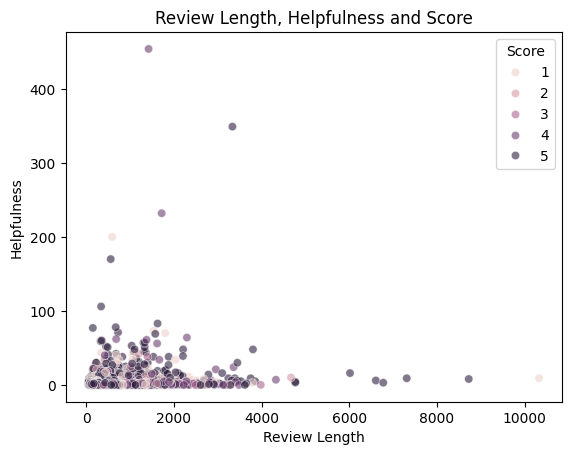

In [65]:
sns.scatterplot(
    data=reviews.sample(10000),
    x='ReviewLength',
    y='HelpfulnessNumerator',
    hue='Score',
    alpha=0.6
)

plt.xlabel('Review Length')
plt.ylabel('Helpfulness')
plt.title('Review Length, Helpfulness and Score')
plt.show()

In [66]:
reviews.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Summary,Text,ReviewLength,HelpfulnessRatio,ReviewDate,Year,Month,YearMonth,Sentiment,summary_word_count
24749,24750,2734888454,A13ISQV0U9GZIC,Sandikaye,1,1,2,made in china,I have bought several of the Vitality canned d...,320,1.000000,2007-10-11,2007,10,2007-10,Negative,3
24750,24751,2734888454,A1C298ITT645B6,Hugh G. Pritchard,0,0,5,Dog Lover Delites,Product arrived labeled as Jumbo Salted Peanut...,150,NaN,2007-11-25,2007,11,2007-11,Positive,3
150525,150526,6641040,A3E9QZFE9KXH8J,R. Mitchell,11,18,1,awesome book poor size,This is a confection that has been around a fe...,231,0.611111,2005-10-17,2005,10,2005-10,Negative,4
150511,150512,6641040,A1DJXZA5V5FFVA,A. Conway,0,0,5,Must have.,If you are looking for the secret ingredient i...,567,NaN,2012-05-29,2012,5,2012-05,Positive,2
150512,150513,6641040,ASH0DZQQF6AIZ,tessarat,0,0,5,A classic,Great taffy at a great price. There was a wide...,203,NaN,2012-01-05,2012,1,2012-01,Positive,2


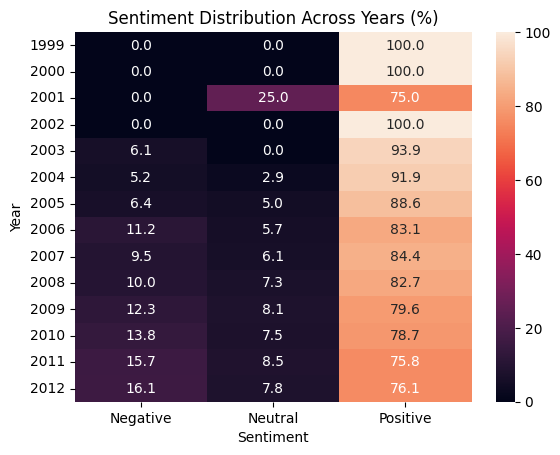

In [67]:
year_sentiment = pd.crosstab(
    reviews['Year'],
    reviews['Sentiment'],
    normalize='index'
) * 100

sns.heatmap(year_sentiment, annot=True, fmt='.1f')

plt.title('Sentiment Distribution Across Years (%)')
plt.xlabel('Sentiment')
plt.ylabel('Year')
plt.show()

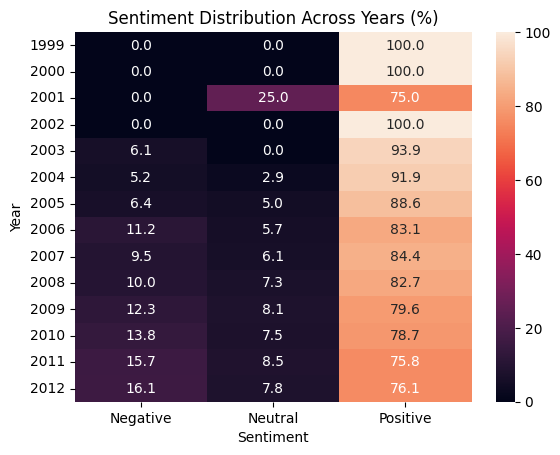

In [68]:
year_sentiment = pd.crosstab(
    reviews['Year'],
    reviews['Sentiment'],
    normalize='index'
) * 100

sns.heatmap(year_sentiment, annot=True, fmt='.1f')

plt.title('Sentiment Distribution Across Years (%)')
plt.xlabel('Sentiment')
plt.ylabel('Year')
plt.show()

In [69]:
product_summary = reviews.groupby('ProductId').agg(
    review_count=('Score', 'size'),
    average_score=('Score', 'mean'),
    average_helpfulness=('HelpfulnessRatio', 'mean')
).sort_values(
    'review_count',
    ascending=False
)

product_summary.head(10)

,review_count,average_score,average_helpfulness
ProductId,,,
B0026RQTGE,630,4.593651,0.855485
B001EO5Q64,566,4.745583,0.911378
B0013NUGDE,562,4.307829,0.874607
B000KV61FC,556,3.411871,0.898658
B005K4Q37A,541,3.817006,0.771341
B003GTR8IO,530,3.813208,0.680009
B005ZBZLT4,506,4.363636,0.771838
B002IEZJMA,487,3.601643,0.485360
B000PDY3P0,486,4.353909,0.836432


In [70]:
user_summary = reviews.groupby('UserId').agg(
    review_count=('Score', 'size'),
    average_score=('Score', 'mean'),
    average_helpfulness=('HelpfulnessRatio', 'mean')
)

user_summary.head()

,review_count,average_score,average_helpfulness
UserId,,,
#oc-R103C0QSV1DF5E,1,5.0,0.500000
#oc-R10UA029WVWIUI,1,1.0,NaN
#oc-R115TNMSPFT9I7,1,2.0,0.666667
#oc-R119LM8D59ZW8Y,1,1.0,0.454545
#oc-R11DNU2NBKQ23Z,1,1.0,NaN


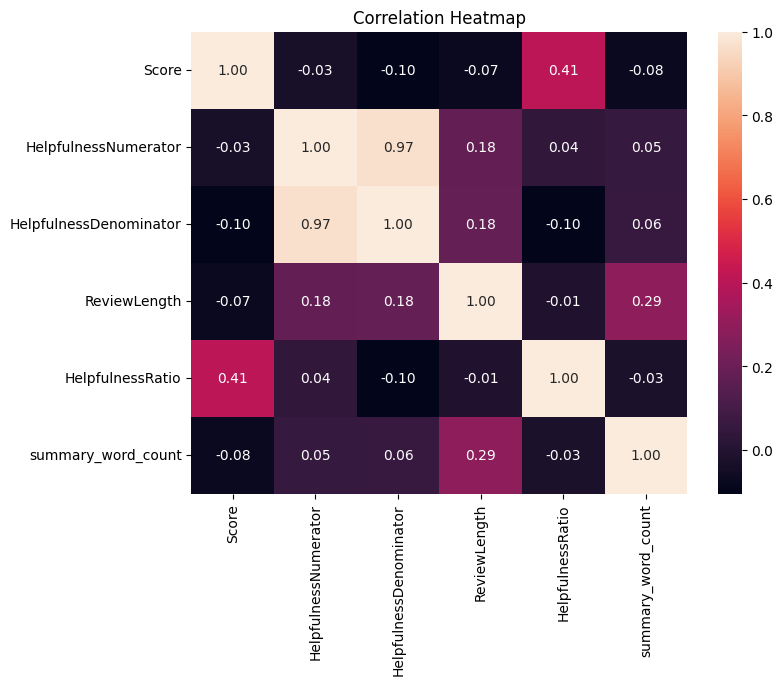

In [71]:
numeric_cols = [
    'Score',
    'HelpfulnessNumerator',
    'HelpfulnessDenominator',
    'ReviewLength',
    'HelpfulnessRatio',
    'summary_word_count'
]

corr = reviews[numeric_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

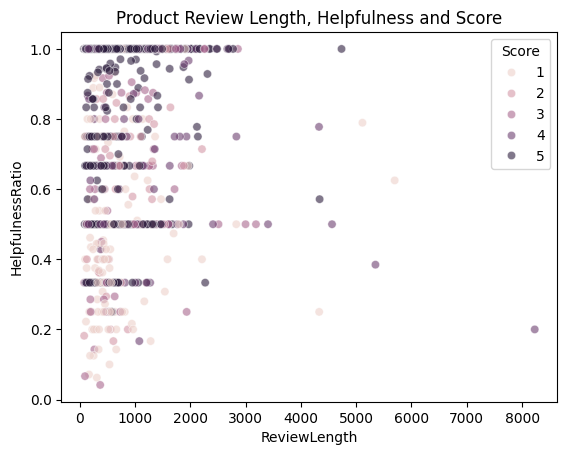

In [72]:
top_products = reviews['ProductId'].value_counts().head(10).index

temp = reviews[reviews['ProductId'].isin(top_products)]

sns.scatterplot(
    data=temp,
    x='ReviewLength',
    y='HelpfulnessRatio',
    hue='Score',
    alpha=0.6
)

plt.title('Product Review Length, Helpfulness and Score')
plt.show()